In [1]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices('GPU')))

# Google Drive connect pannu
from google.colab import drive
drive.mount('/content/drive')
print("Drive Connected!")

TensorFlow: 2.21.0
GPU Available: 1
Mounted at /content/drive
Drive Connected!


In [8]:
# CODE 2 - Dataset Download and Extraction
!pip install -q gdown
import gdown, zipfile, os

file_id = "1Rj0EYgDy0sy7jc7-KXvQiHwpqA0Dzj__"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "drowsiness.zip", quiet=False, fuzzy=True)
print("File size:", os.path.getsize("drowsiness.zip") // (1024*1024), "MB")

with zipfile.ZipFile("drowsiness.zip", 'r') as z:
    z.extractall("drowsiness_data")
    print("Files:", z.namelist()[:10])

print("DONE!")
for root, dirs, files in os.walk("drowsiness_data"):
    if root.count(os.sep) < 4:
        print(root, "->", dirs[:5], "files:", len(files))

Downloading...
From (original): https://drive.google.com/uc?id=1Rj0EYgDy0sy7jc7-KXvQiHwpqA0Dzj__
From (redirected): https://drive.google.com/uc?id=1Rj0EYgDy0sy7jc7-KXvQiHwpqA0Dzj__&confirm=t&uuid=19e492de-b44e-498f-a7e2-fd3b651ac973
To: /content/drowsiness.zip
100%|██████████| 169M/169M [00:04<00:00, 40.6MB/s]


File size: 160 MB
Files: ['train/Closed/_0.jpg', 'train/Closed/_1.jpg', 'train/Closed/_10.jpg', 'train/Closed/_100.jpg', 'train/Closed/_101.jpg', 'train/Closed/_102.jpg', 'train/Closed/_103.jpg', 'train/Closed/_104.jpg', 'train/Closed/_105.jpg', 'train/Closed/_106.jpg']
DONE!
drowsiness_data -> ['train'] files: 0
drowsiness_data/train -> ['yawn', 'Closed', 'Open', 'no_yawn'] files: 0
drowsiness_data/train/yawn -> [] files: 723
drowsiness_data/train/Closed -> [] files: 726
drowsiness_data/train/Open -> [] files: 726
drowsiness_data/train/no_yawn -> [] files: 725


Closed: 726 images
Open: 726 images
yawn: 723 images
no_yawn: 725 images


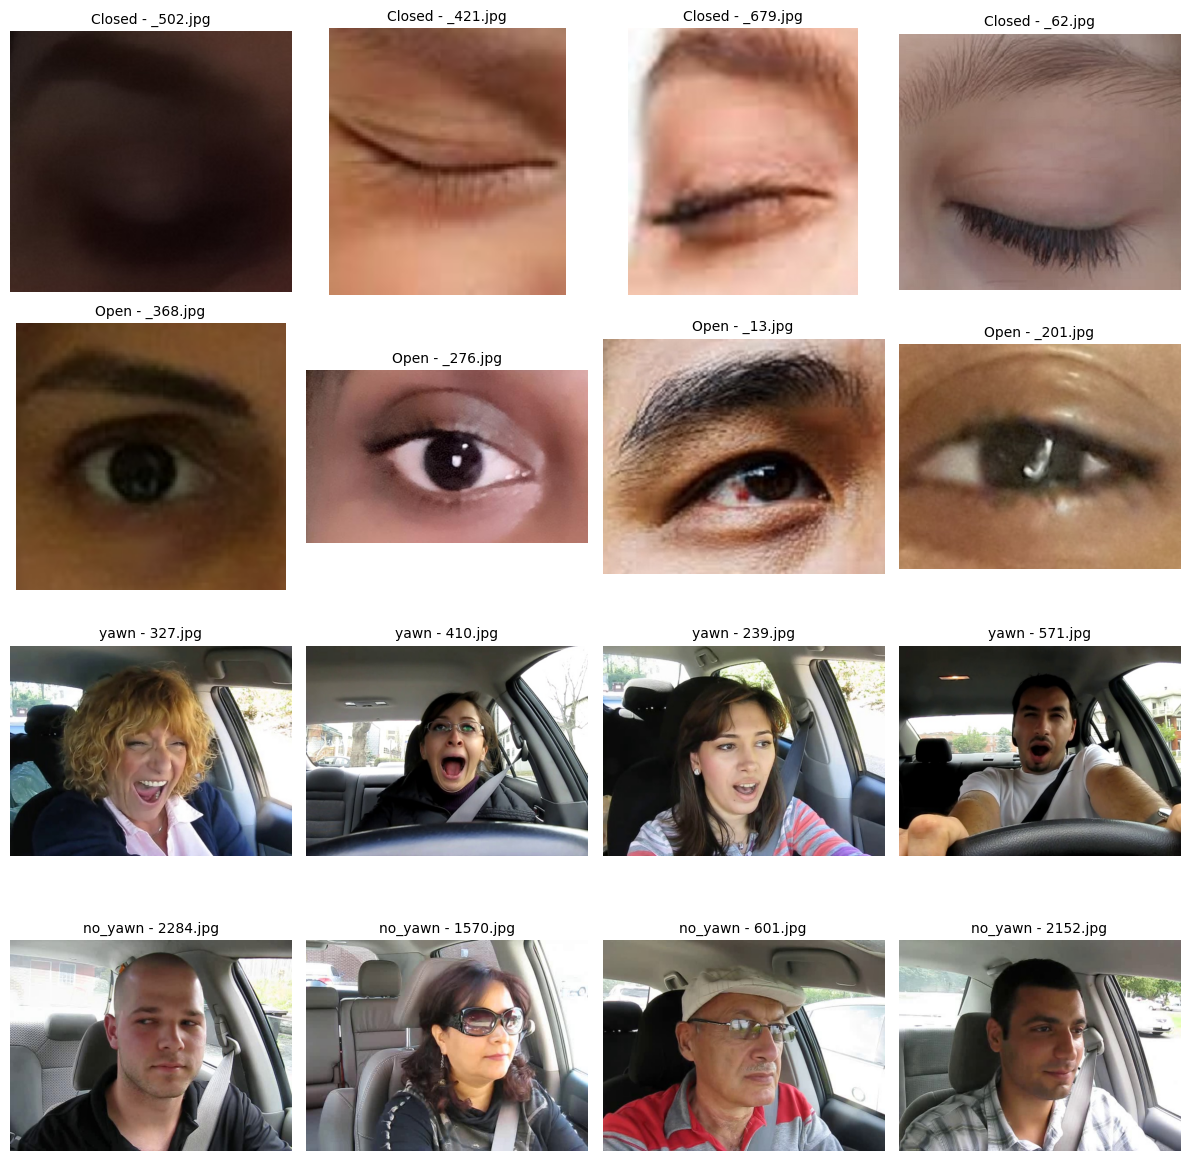

In [9]:
# CODE 3 - Data Exploration and Sample Visualization
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

base_path = "drowsiness_data/train"
classes = ["Closed", "Open", "yawn", "no_yawn"]

# Count images per class
for cls in classes:
    folder = os.path.join(base_path, cls)
    count = len(os.listdir(folder))
    print(f"{cls}: {count} images")

# Display sample images - 4 rows (one per class), 4 columns
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, cls in enumerate(classes):
    folder = os.path.join(base_path, cls)
    files = os.listdir(folder)
    samples = random.sample(files, 4)
    for j, fname in enumerate(samples):
        img_path = os.path.join(folder, fname)
        img = Image.open(img_path)
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{cls} - {fname}", fontsize=10)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# CODE 4 - Data Preparation with Augmentation
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Training data - Augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

# Validation data - Only rescaling
val_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    "drowsiness_data/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    "drowsiness_data/train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("Class Indices:", train_generator.class_indices)
print("Training Samples:", train_generator.samples)
print("Validation Samples:", val_generator.samples)

Found 2321 images belonging to 4 classes.
Found 579 images belonging to 4 classes.
Class Indices: {'Closed': 0, 'Open': 1, 'no_yawn': 2, 'yawn': 3}
Training Samples: 2321
Validation Samples: 579


In [11]:
# CODE 5 - Model Building with MobileNetV2
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

IMG_SIZE = (224, 224, 3)
NUM_CLASSES = 4

# Base Model - Pre-trained on ImageNet
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=IMG_SIZE
)
base_model.trainable = False

# Custom Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=outputs)

# Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,430,468 (9.27 MB)

 Trainable params: 172,484 (673.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
# CODE 6 - Model Training
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

EPOCHS = 12

# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_drowsiness_model.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

# Train Model
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint]
)

print("Training Completed")

Epoch 1/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.6382 - loss: 0.7135

73/73 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.7225 - loss: 0.5166 - val_accuracy: 0.8307 - val_loss: 0.3442
Epoch 2/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 41s 569ms/step - accuracy: 0.8100 - loss: 0.3436 - val_accuracy: 0.7979 - val_loss: 0.3565
Epoch 3/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 42s 570ms/step - accuracy: 0.8307 - loss: 0.3267 - val_accuracy: 0.7789 - val_loss: 0.3727
Epoch 4/12
73/73 ━━━━━━━━━━━━━━━━━━━━ 39s 537ms/step - accuracy: 0.8445 - loss: 0.3040 - val_accuracy: 0.7945 - val_loss: 0.3570
Training Completed


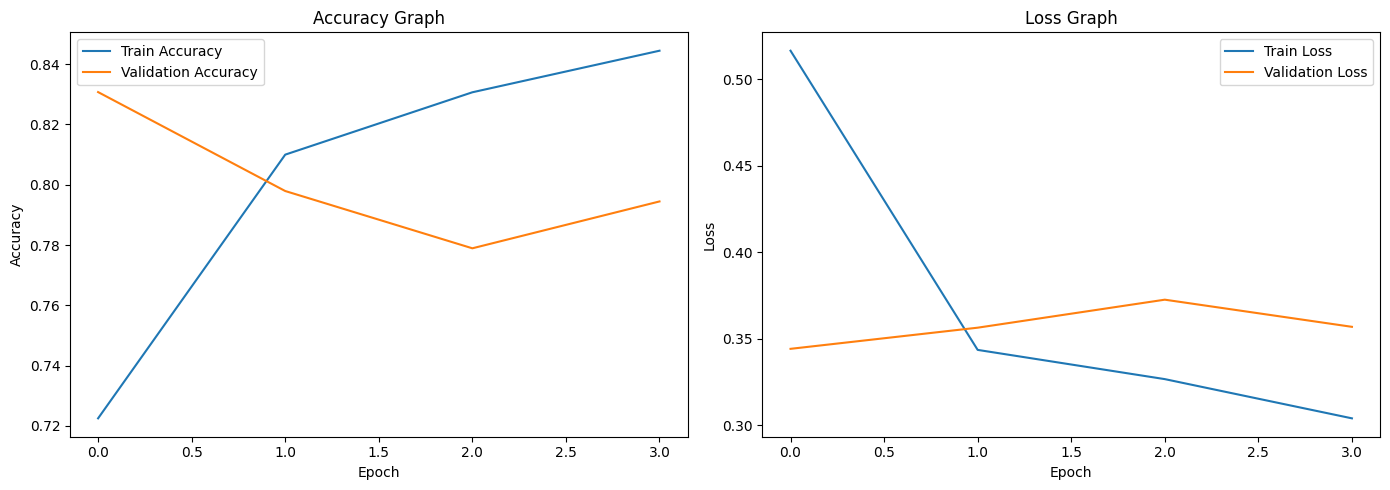

              precision    recall  f1-score   support

      Closed       0.96      0.98      0.97       145
        Open       0.98      0.96      0.97       145
     no_yawn       0.64      0.88      0.74       145
        yawn       0.81      0.50      0.62       144

    accuracy                           0.83       579
   macro avg       0.85      0.83      0.82       579
weighted avg       0.85      0.83      0.82       579



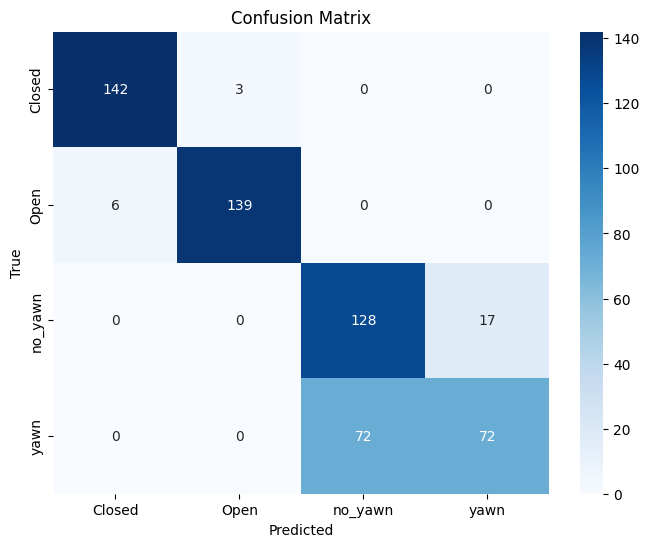

In [13]:
# CODE 7 - Model Evaluation
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Accuracy and Loss Graph
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy Graph")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss Graph")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

# Predictions
val_generator.reset()
preds = model.predict(val_generator, verbose=0)
y_pred = np.argmax(preds, axis=1)
y_true = val_generator.classes
labels = list(val_generator.class_indices.keys())

# Classification Report
print(classification_report(y_true, y_pred, target_names=labels))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [14]:
# CODE 8 - Single Image Prediction and Drowsiness Logic
import numpy as np
import os
import random
from tensorflow.keras.preprocessing import image

labels = ["Closed", "Open", "no_yawn", "yawn"]

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    pred = model.predict(img_array, verbose=0)
    class_id = np.argmax(pred)
    confidence = np.max(pred) * 100
    return labels[class_id], confidence

def check_drowsiness(predicted_class):
    if predicted_class in ["Closed", "yawn"]:
        return "DROWSY - ALERT!"
    else:
        return "ALERT - SAFE"

# Test on 4 random images - One from each class
base_path = "drowsiness_data/train"
for cls in labels:
    folder = os.path.join(base_path, cls)
    fname = random.choice(os.listdir(folder))
    full_path = os.path.join(folder, fname)
    pred_class, conf = predict_image(full_path)
    status = check_drowsiness(pred_class)
    print(f"True: {cls} | Predicted: {pred_class} | Confidence: {conf:.1f}% | Status: {status}")

True: Closed | Predicted: Closed | Confidence: 99.8% | Status: DROWSY - ALERT!
True: Open | Predicted: Open | Confidence: 100.0% | Status: ALERT - SAFE
True: no_yawn | Predicted: no_yawn | Confidence: 53.8% | Status: ALERT - SAFE
True: yawn | Predicted: no_yawn | Confidence: 55.5% | Status: ALERT - SAFE


In [15]:
# CODE 9 - Save Final Model
import os
from google.colab import files

model.save("drowsiness_final_model.h5")
print("Model Saved")

# Check file size
size_mb = os.path.getsize("drowsiness_final_model.h5") // (1024 * 1024)
print(f"File Size: {size_mb} MB")

# Copy to Drive for Backup
!cp drowsiness_final_model.h5 /content/drive/MyDrive/drowsiness_final_model.h5
print("Backup Saved to Drive")

# Download to Laptop
files.download("drowsiness_final_model.h5")

Model Saved
File Size: 11 MB
Backup Saved to Drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>